In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=374)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

                 date  lights     T1       RH_1    T2       RH_2     T3  \
0  2016-01-1117:00:00      30  19.89  47.596667  19.2  44.790000  19.79   
1  2016-01-1117:10:00      30  19.89  46.693333  19.2  44.722500  19.79   
2  2016-01-1117:20:00      30  19.89  46.300000  19.2  44.626667  19.79   
3  2016-01-1117:30:00      40  19.89  46.066667  19.2  44.590000  19.79   
4  2016-01-1117:40:00      40  19.89  46.333333  19.2  44.530000  19.79   

        RH_3         T4       RH_4  ...   RH_9  T_out  Press_mm_hg  RH_out  \
0  44.730000  19.000000  45.566667  ...  45.53   6.60        733.5    92.0   
1  44.790000  19.000000  45.992500  ...  45.56   6.48        733.6    92.0   
2  44.933333  18.926667  45.890000  ...  45.50   6.37        733.7    92.0   
3  45.000000  18.890000  45.723333  ...  45.40   6.25        733.8    92.0   
4  45.000000  18.890000  45.530000  ...  45.40   6.13        733.9    92.0   

   Windspeed  Visibility  Tdewpoint        rv1        rv2  Appliances  
0   7.00

In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values:
date           0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
Appliances     0
dtype: int64

Total Missing Values:
0


In [6]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [9]:
df['date'] = df['date'].astype(str).str.replace(
    r'^(\d{4}-\d{2}-\d{2})(\d{2}:\d{2}:\d{2})$',
    r'\1 \2',
    regex=True
)

# Convert date into datetime format
df['date'] = pd.to_datetime(
    df['date'],
    format='%Y-%m-%d %H:%M:%S'
)

# Sort data according to date
df = df.sort_values('date')

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values
df = df.fillna(df.median(numeric_only=True))

print("Data Cleaning Completed!")
print("Dataset Shape:", df.shape)


Data Cleaning Completed!
Dataset Shape: (19735, 29)


In [10]:
df['hour'] = df['date'].dt.hour
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['dayofweek'] = df['date'].dt.dayofweek

# Remove original date column
df = df.drop('date', axis=1)

print("Date Features Created Successfully!")
print(df.head())


Date Features Created Successfully!
   lights     T1       RH_1    T2       RH_2     T3       RH_3         T4  \
0      30  19.89  47.596667  19.2  44.790000  19.79  44.730000  19.000000   
1      30  19.89  46.693333  19.2  44.722500  19.79  44.790000  19.000000   
2      30  19.89  46.300000  19.2  44.626667  19.79  44.933333  18.926667   
3      40  19.89  46.066667  19.2  44.590000  19.79  45.000000  18.890000   
4      40  19.89  46.333333  19.2  44.530000  19.79  45.000000  18.890000   

        RH_4         T5  ...  Windspeed  Visibility  Tdewpoint        rv1  \
0  45.566667  17.166667  ...   7.000000   63.000000        5.3  13.275433   
1  45.992500  17.166667  ...   6.666667   59.166667        5.2  18.606195   
2  45.890000  17.166667  ...   6.333333   55.333333        5.1  28.642668   
3  45.723333  17.166667  ...   6.000000   51.500000        5.0  45.410390   
4  45.530000  17.200000  ...   5.666667   47.666667        4.9  10.084097   

         rv2  Appliances  hour  day  m

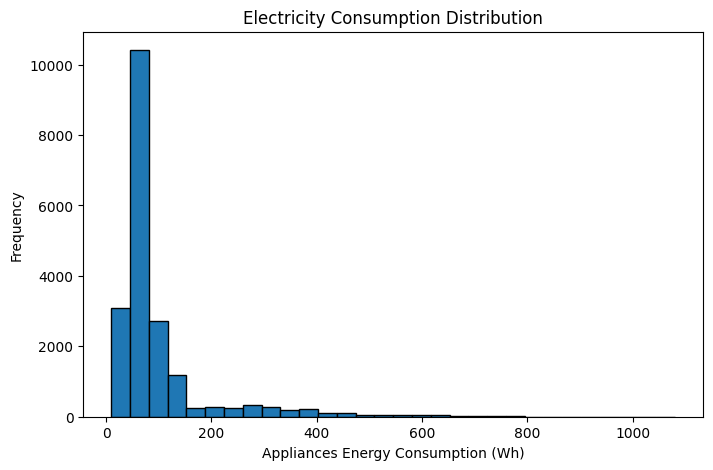

In [11]:
plt.figure(figsize=(8,5))

plt.hist(df['Appliances'], bins=30, edgecolor='black')

plt.title('Electricity Consumption Distribution')
plt.xlabel('Appliances Energy Consumption (Wh)')
plt.ylabel('Frequency')

plt.show()


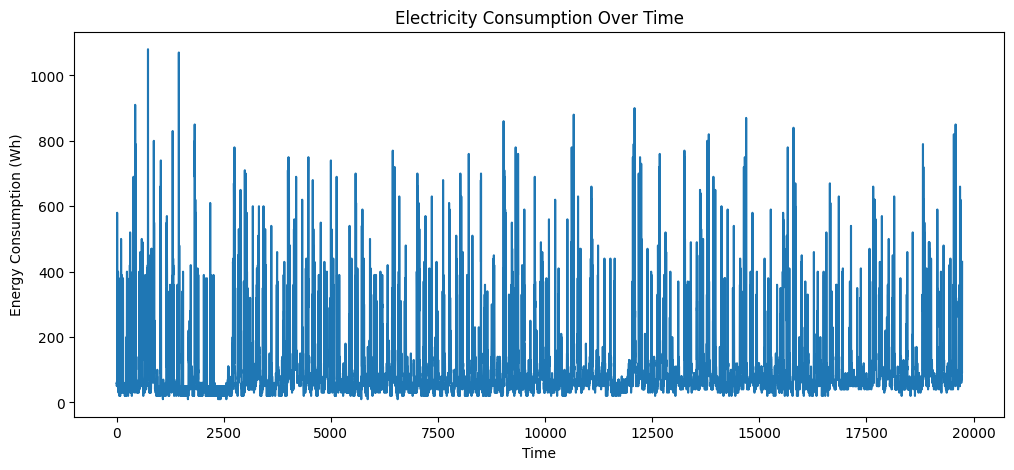

In [12]:
plt.figure(figsize=(12,5))

plt.plot(df.index, df['Appliances'])

plt.title('Electricity Consumption Over Time')
plt.xlabel('Time')
plt.ylabel('Energy Consumption (Wh)')

plt.show()


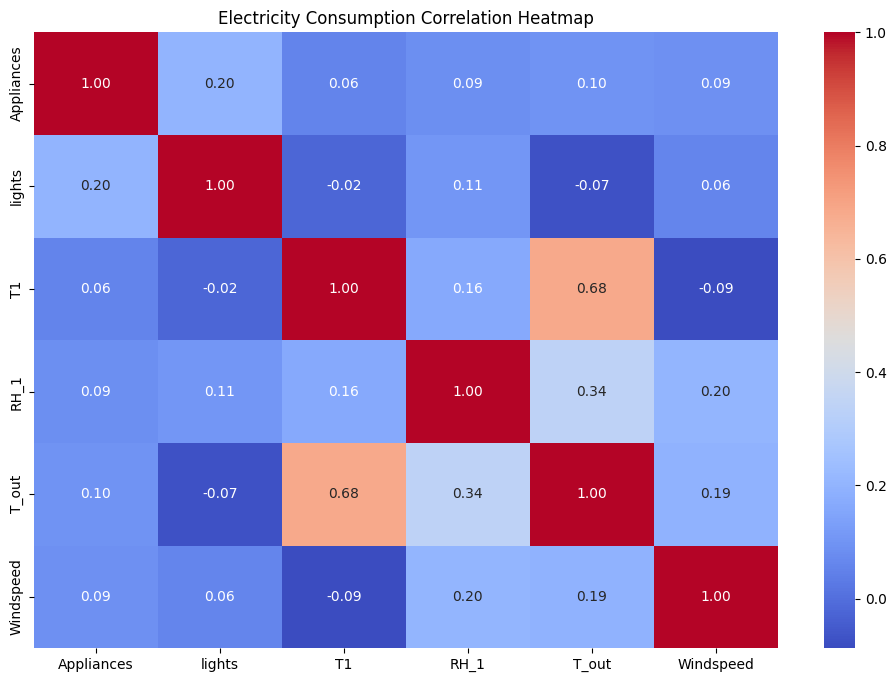

In [13]:
plt.figure(figsize=(12,8))

correlation = df[['Appliances', 'lights', 'T1',
                  'RH_1', 'T_out', 'Windspeed']].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title('Electricity Consumption Correlation Heatmap')

plt.show()

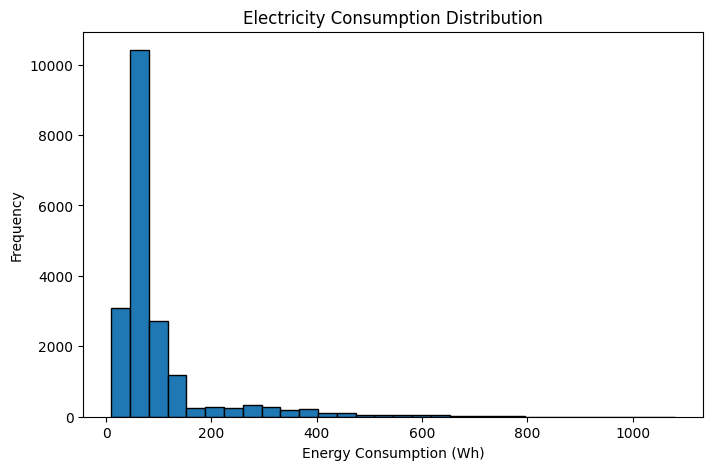

Graph saved successfully!


In [14]:
import os

os.makedirs('graphs', exist_ok=True)

plt.figure(figsize=(8,5))
plt.hist(df['Appliances'], bins=30, edgecolor='black')
plt.title('Electricity Consumption Distribution')
plt.xlabel('Energy Consumption (Wh)')
plt.ylabel('Frequency')
plt.savefig('graphs/consumption_distribution.png')
plt.show()

print("Graph saved successfully!")


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine Learning libraries imported successfully!")


Machine Learning libraries imported successfully!


In [16]:
X = df.drop('Appliances', axis=1)
y = df['Appliances']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (15788, 31)
Testing Data: (3947, 31)


In [17]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [18]:
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")


Decision Tree Model Trained Successfully!


In [19]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


In [20]:
models = {
    'Linear Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'Gradient Boosting': gb_predictions
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, r2])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'R2 Score']
)

print(results_df)


               Model         MAE           MSE  R2 Score
0  Linear Regression   49.773595   7384.360507  0.109031
1      Decision Tree  163.478447  60930.970810 -6.351697
2  Gradient Boosting  178.972766  50783.087190 -5.127293


In [21]:
best_model_name = results_df.loc[
    results_df['MAE'].idxmin(), 'Model'
]

if best_model_name == 'Linear Regression':
    best_model = lr_model

elif best_model_name == 'Decision Tree':
    best_model = dt_model

else:
    best_model = gb_model

print("Best Model:", best_model_name)
print("Best Model Selected Successfully!")


Best Model: Linear Regression
Best Model Selected Successfully!


In [22]:
sample_data = X_test.iloc[[0]]

prediction = best_model.predict(sample_data)

actual = y_test.iloc[0]

print("Actual Electricity Consumption:", actual, "Wh")
print("Predicted Electricity Consumption:", round(prediction[0], 2), "Wh")

Actual Electricity Consumption: 370 Wh
Predicted Electricity Consumption: 72.51 Wh


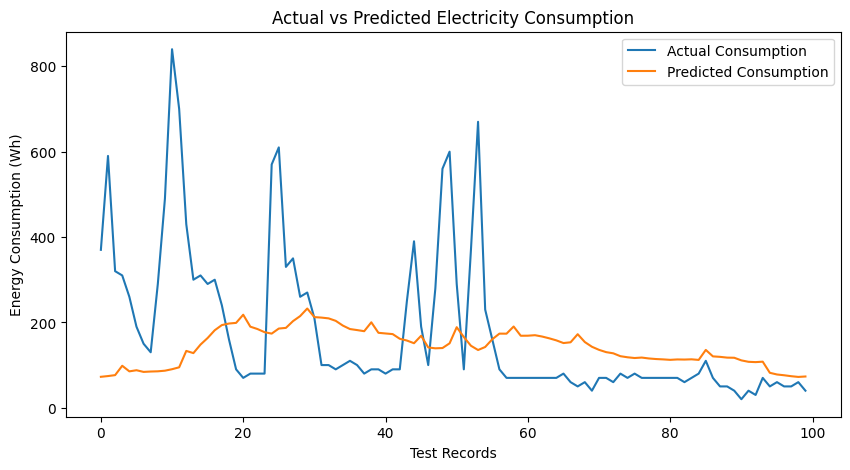

In [23]:
plt.figure(figsize=(10,5))

plt.plot(
    y_test.iloc[:100].values,
    label='Actual Consumption'
)

plt.plot(
    best_model.predict(X_test.iloc[:100]),
    label='Predicted Consumption'
)

plt.title('Actual vs Predicted Electricity Consumption')
plt.xlabel('Test Records')
plt.ylabel('Energy Consumption (Wh)')

plt.legend()
plt.show()


In [24]:
def predict_electricity(row_number):

    sample = X_test.iloc[[row_number]]

    result = best_model.predict(sample)

    print("Selected Record:", row_number)
    print("Predicted Electricity Consumption:",
          round(result[0], 2), "Wh")

predict_electricity(5)


Selected Record: 5
Predicted Electricity Consumption: 87.92 Wh


In [25]:
import joblib
import os

os.makedirs('model', exist_ok=True)

joblib.dump(best_model, 'model/electricity_model.pkl')

print("Machine Learning Model Saved Successfully!")

Machine Learning Model Saved Successfully!


In [26]:
os.makedirs('results', exist_ok=True)

results_df.to_csv('results/model_comparison.csv', index=False)

print("Model Results Saved Successfully!")


Model Results Saved Successfully!


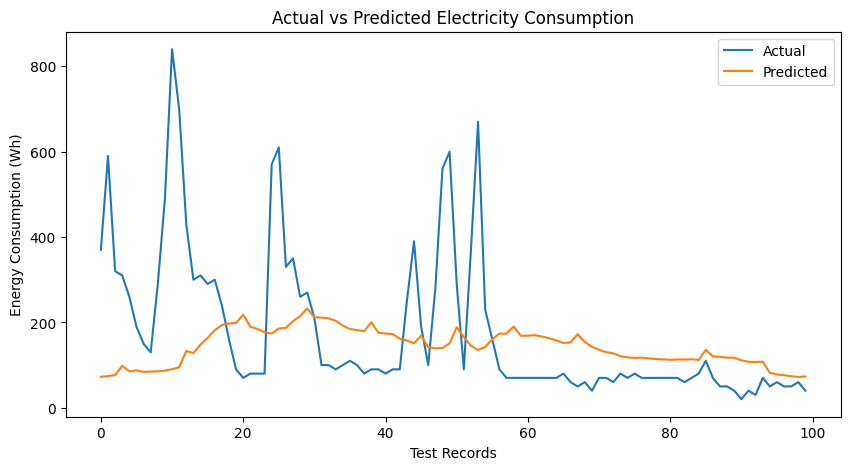

Prediction Graph Saved Successfully!


In [27]:
plt.figure(figsize=(10,5))

plt.plot(y_test.iloc[:100].values, label='Actual')
plt.plot(best_model.predict(X_test.iloc[:100]), label='Predicted')

plt.title('Actual vs Predicted Electricity Consumption')
plt.xlabel('Test Records')
plt.ylabel('Energy Consumption (Wh)')

plt.legend()
plt.savefig('graphs/actual_vs_predicted.png')

plt.show()

print("Prediction Graph Saved Successfully!")


## Machine Learning Algorithms
1. Linear Regression
2. Decision Tree Regression
3. Gradient Boosting Regression

## Evaluation Metrics
- MAE
- MSE
- R2 Score

## Project Output
The project predicts electricity consumption
and compares actual and predicted values.
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README file created successfully!")


In [28]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
ucimlrepo
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("Requirements file created successfully!")


Requirements file created successfully!


In [29]:
import os

print(os.path.exists("requirements.txt"))
print(os.listdir())


True
['.config', 'graphs', 'results', 'model', 'requirements.txt', 'sample_data']


In [30]:
import shutil
from google.colab import files

shutil.make_archive(
    'Electricity_Consumption_Project',
    'zip',
    '.',
    'graphs'
)

files.download('Electricity_Consumption_Project.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>